# 24. Ensemble: classical method + model

Several members judge the same tile and one rule combines them. Background subtraction (classical, pixel level) finds small sharp defects; PatchCore (model, patch level) finds faint texture changes. They miss different damage, so together they catch more.

How it works: every member's tile score is standardised with its own good_cal statistics (`z` = how many robust deviations above good fabric), so the members are on the same scale. `RULE` combines the `z` values: `max` = damaged if any member flags, `mean` = average, `min` = damaged only if all flag.

Evaluation: `evaluate.py`, same split and same test tiles as every other experiment (README section 7). Members are fitted and calibrated on good_cal strips only. Results are saved to `results/ensemble/`.

In [5]:
import sys, importlib

sys.path.insert(0, "../src/methods")
import filters as F    # classical methods
import evaluate as E   # shared evaluation (README section 7) + ensemble
import models as M     # PatchCore and PaDiM (needs torch + torchvision)
importlib.reload(F); importlib.reload(E); importlib.reload(M)  # pick up edits without restarting the kernel
print(M.device_info())

# ---- evaluation settings (same for every experiment) ----------------------
FABRIC = "02"           # fabric code = third part of the file name
METHOD_NAME = "ensemble"  # results go to results/<METHOD_NAME>/
THR_K = 4.0             # a member flags a tile when its score is THR_K robust deviations above good fabric
MIN_AREA = 4            # damage mask: drop spots smaller than this (px); keep <= 4
SCORE_K = 25            # tile score = mean of the SCORE_K highest values of the smoothed map
SCORE_SIGMA = 2.0       # smoothing before scoring (px)
FIT_FRACTION = 0.7      # models: this share of the good_cal strips trains the model, the rest sets thresholds
SETTINGS = dict(thr_k=THR_K, min_area=MIN_AREA, score_k=SCORE_K, score_sigma=SCORE_SIGMA,
                fit_fraction=FIT_FRACTION)

# ---- ensemble settings ------------------------------------------------------
RULE = "max"   # "max"  = damaged if ANY member flags the tile (catches most, more false alarms)
               # "mean" = average of the members' scores
               # "min"  = damaged only if ALL members flag it (fewest false alarms, misses more)


def fit_patchcore(good_tiles):
    """PatchCore memory bank from good tiles only (settings as in 22_patchcore)."""
    fitted = M.fit_patchcore(good_tiles, backbone="wide_resnet50_2", layers=("layer2", "layer3"),
                             coreset=0.01, n_neighbors=1, pool=3, smooth=4.0)
    return lambda tile: M.patchcore_map(tile, fitted)


# Members: a classical method is dict(method=tile -> map); a model is dict(fit=...).
# Add or remove lines to change the ensemble, e.g.  "wavelet": dict(method=lambda t: F.wavelet(t)),
MEMBERS = {
    "background_subtraction": dict(method=lambda t: F.background_subtraction(t)),   # strong on small, sharp defects
    "patchcore": dict(fit=fit_patchcore),                                           # strong on faint texture changes
}

torch 2.15.0+cpu, device: cpu (no GPU found: slower, still works)


## Results for one fabric
Every member alone and every rule, on the same test tiles (one run). FAR = false alarm rate on good_test, FAR hn = on clean tiles of defective strips.

In [6]:
res = E.evaluate_ensemble(MEMBERS, FABRIC, RULE, **SETTINGS)
assert res is not None, f"not enough tiles for fabric {FABRIC}"
table = E.ensemble_table(res)
print("\nsaved to", E.save_ensemble(res, METHOD_NAME))

  configuration                     FAR  FAR hn  recall  small  large  AUROC
----------------------------------------------------------------------------
  background_subtraction alone     1.4%    3.4%   89.5%  82.6% 100.0%  0.984
  patchcore alone                  0.0%    2.2%   34.2%  17.4%  60.0%  0.872
* rule max                         1.4%    4.9%   89.5%  82.6% 100.0%  0.978
  rule mean                        0.0%    2.4%   44.7%  34.8%  60.0%  0.980
  rule min                         0.0%    0.8%   52.6%  39.1%  73.3%  0.935

FAR = false alarm rate on good_test, FAR hn = on clean tiles of defective strips. fabric 02, 2 members, rule = max

saved to C:\Users\chanupa.d\Documents\concord\fabric inspection\results\ensemble


### Recall per defect type (ensemble, rule = `RULE`)

In [7]:
E.print_by_type(res)

defect   tiles  found   recall  mean IoU  median area  median score
002          1      1     100%      0.13          151          5.45
006          7      7     100%      0.33         1260         44.57
019         23     20      87%      0.39           15          6.01
023          3      3     100%      0.13          778          8.07
030          4      3      75%      0.35           70          7.43


### Failure cases
Missed defects and false alarms of the ensemble. Each picture shows every member's anomaly map and whether that member flagged the tile. Red = detected, green = ground-truth mask.

4 missed defects, 27 false alarms


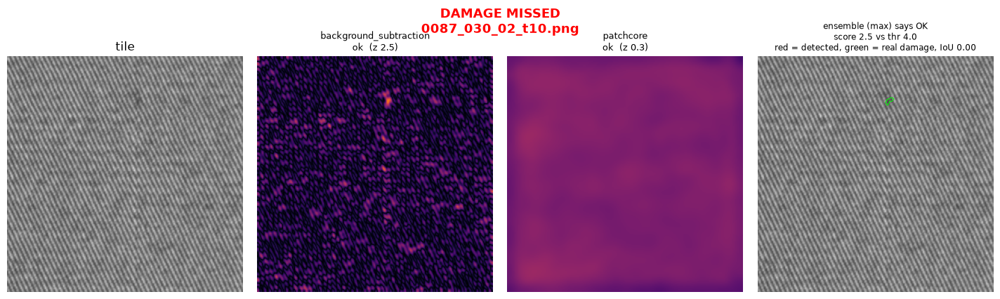

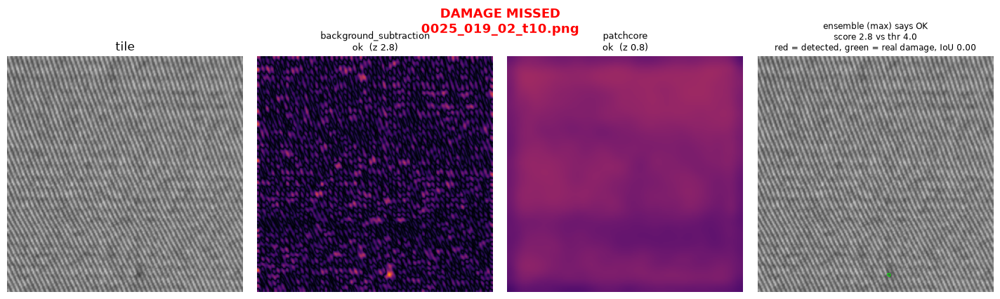

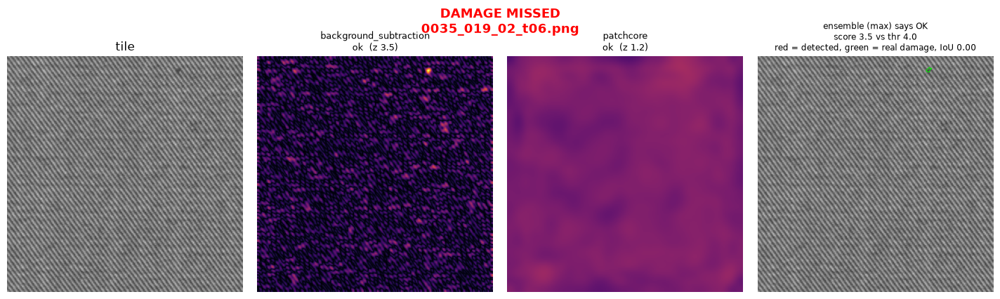

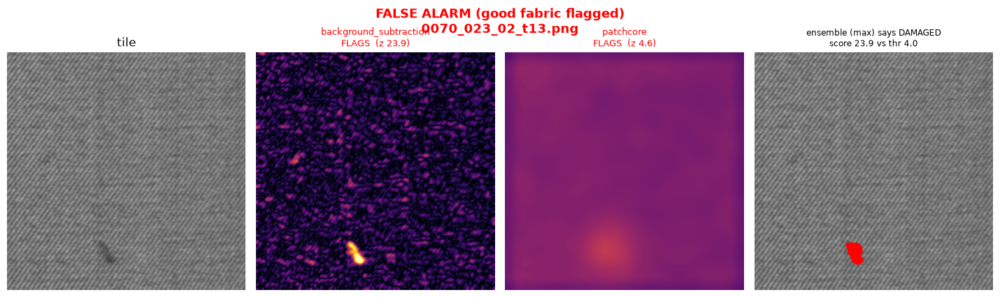

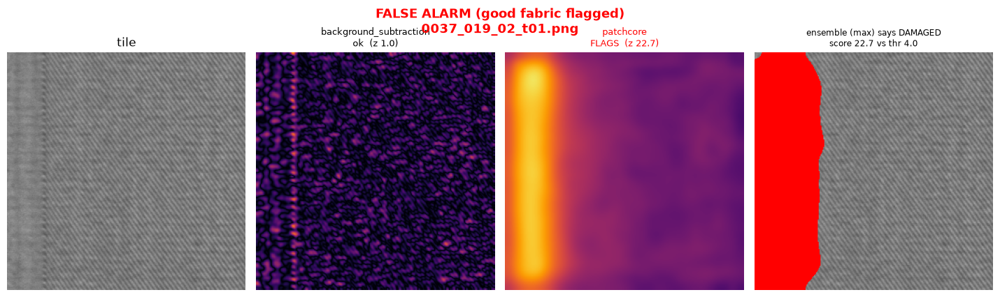

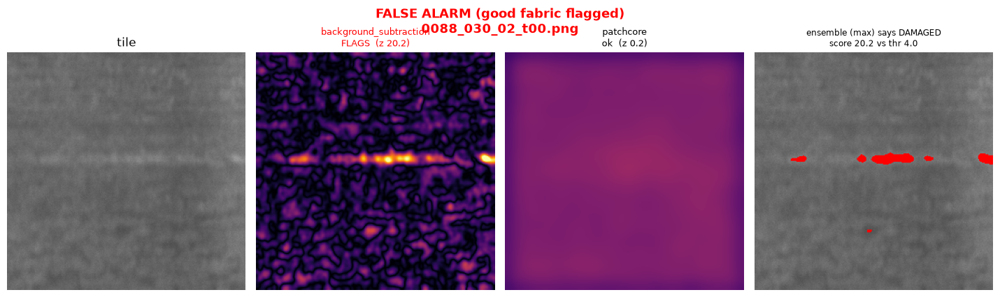

In [8]:
E.show_ensemble_failures(res, n=3)

### One example per defect type
One tile per defect type (the clearest one), judged by an ensemble fitted and calibrated on its own fabric (other fabrics are fitted here, so this cell takes longer). The table says which member caught it.

type   fabric  tiles  example tile           area px   score    thr  result
002        01     10  0005_002_01_t08.png       2514    22.0    4.0  DAMAGED (caught)  members flagging: background_subtraction, patchcore
006        02      9  0016_006_02_t12.png       2111    59.9    4.0  DAMAGED (caught)  members flagging: background_subtraction, patchcore
010        03     63  0103_010_03_t12.png      19060    18.4    4.0  DAMAGED (caught)  members flagging: patchcore
016        03      7  0021_016_03_t14.png        823    37.7    4.0  DAMAGED (caught)  members flagging: background_subtraction, patchcore
019        02     40  0023_019_02_t08.png         54     5.5    4.0  DAMAGED (caught)  members flagging: background_subtraction
022        00     12  0065_022_00_t05.png        473    18.4    4.0  DAMAGED (caught)  members flagging: background_subtraction, patchcore
023        01      6  0067_023_01_t09.png        577    10.1    4.0  DAMAGED (caught)  members flagging: background_subtracti

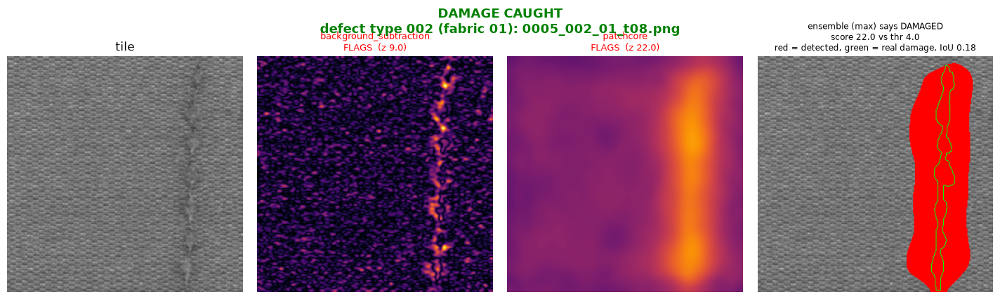

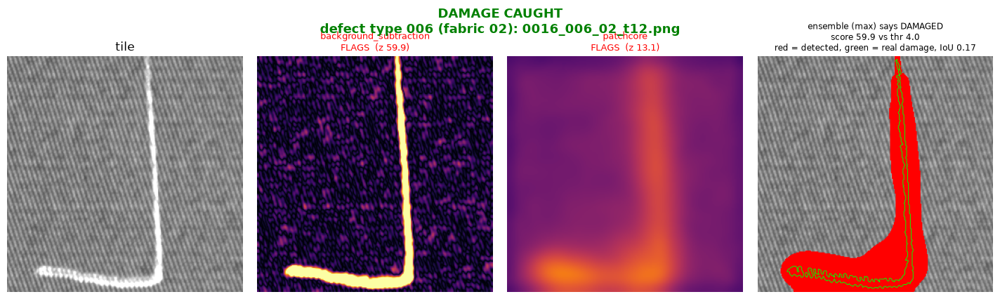

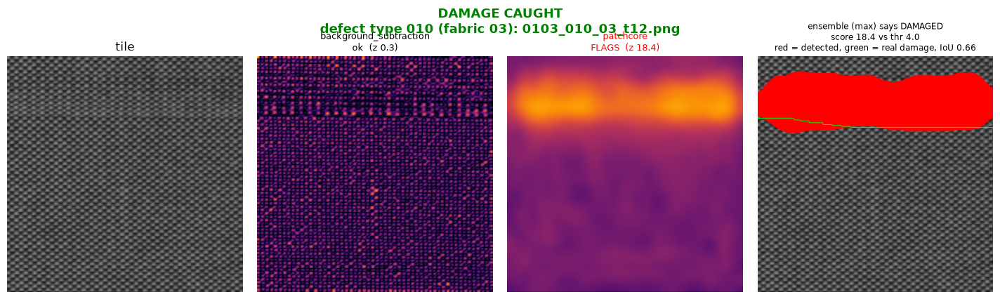

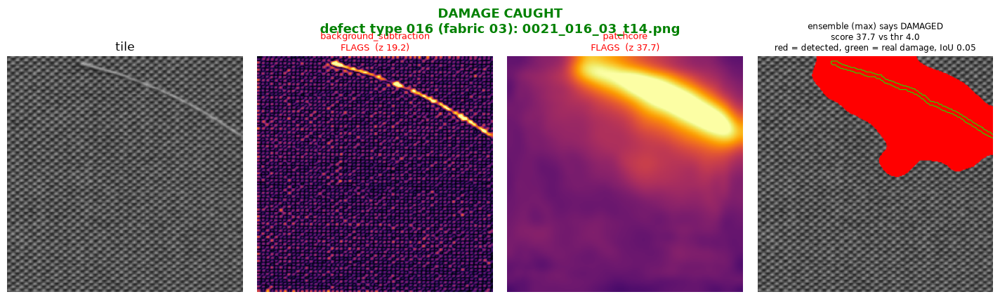

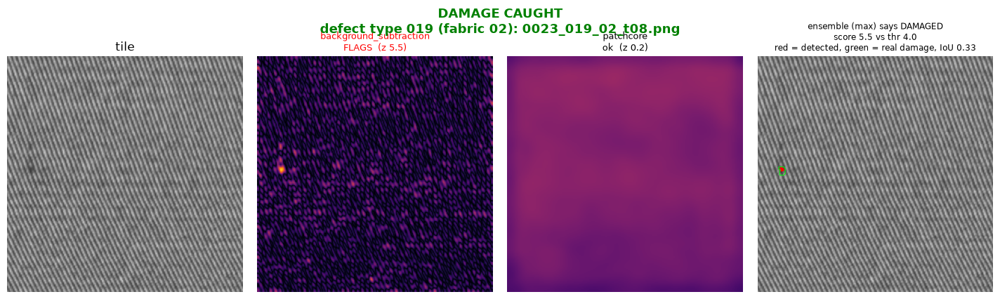

...

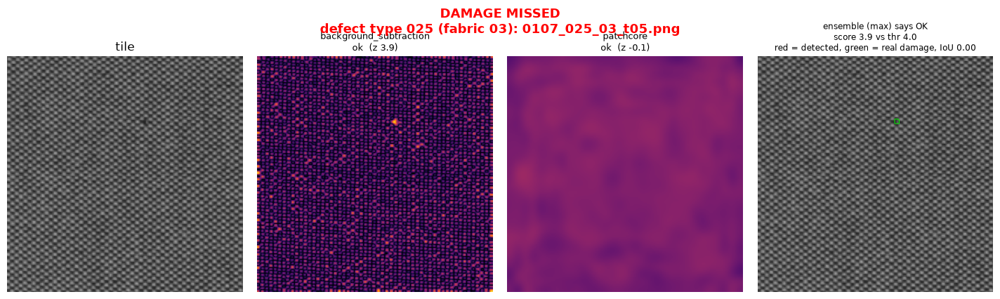

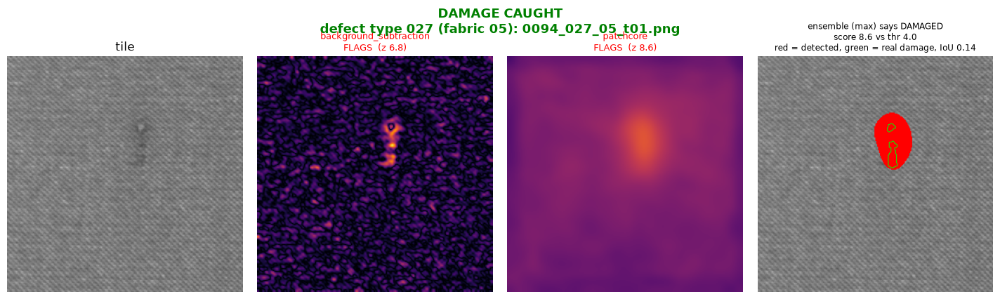

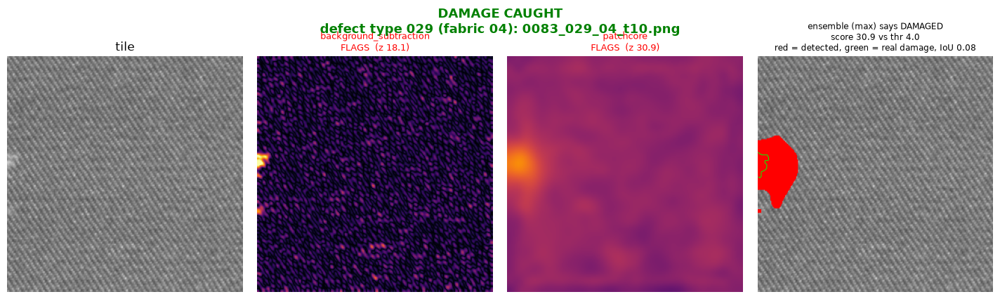

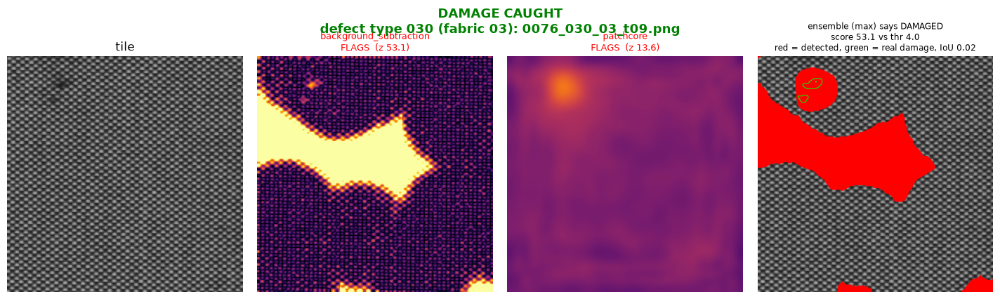

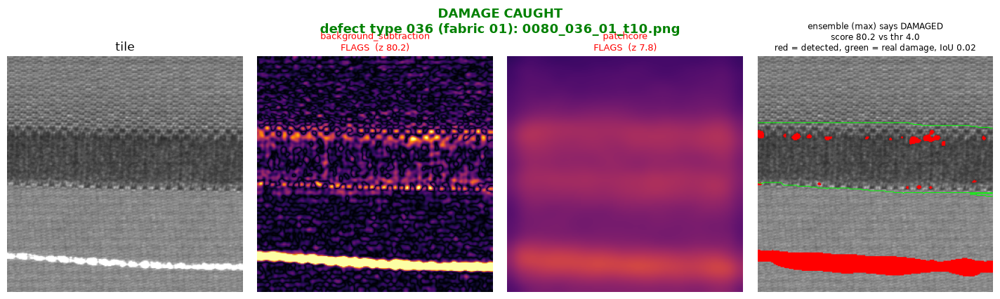

In [9]:
E.ensemble_per_type(MEMBERS, res, RULE, **SETTINGS)

## All fabrics
Same ensemble on every fabric, fitted and calibrated per fabric. The first table is the ensemble with `RULE`; below it, every member alone and every rule over all fabrics together.

In [10]:
summaries = E.ensemble_all_fabrics(MEMBERS, METHOD_NAME, RULE, **SETTINGS)

fabric   test  hard defect    FAR  FAR hn  recall  small  large stripFAR stripRec  AUROC   IoU    ms
----------------------------------------------------------------------------------------------------
00        110    76      9  12.7%   38.2%  100.0% 100.0% 100.0%    80.0%   100.0%  0.991  0.06 382.4
01        154   146     28   5.8%    8.2%   96.4%  50.0% 100.0%    18.2%   100.0%  0.985  0.06 377.0
02        140   507     38   1.4%    4.9%   89.5%  82.6% 100.0%    20.0%    89.5%  0.978  0.35 386.8
03        110   256     89   0.0%    7.4%   75.3%  84.6%  73.7%     0.0%    93.3%  0.903  0.12 380.3
04        138   129     12   7.2%   13.2%  100.0% 100.0% 100.0%    80.0%   100.0%  0.987  0.08 387.8
05        150    13      1   5.3%    0.0%  100.0%    n/a 100.0%    60.0%   100.0%  0.988  0.14 410.3
06        143    81      7  14.7%   24.7%   85.7%  80.0% 100.0%   100.0%   100.0%  0.946  0.01 563.2
-------------------------------------------------------------------------------------------